# S12 · 05 — Transformers y LLM: tokenización y atención paso a paso


Equipo: 5 Green

Integrantes: Cristina, Miguel, Fran, Andri, Anzhela

Contexto: TurisData Canarias

Fecha: 24-25.11.2026

scrum master Miguel, técnico Anzela


Sprint 12 · UD 4.9

**Contexto TurisData.** Antes de que TurisData use un LLM como asistente, su equipo debe entender qué hay dentro de la "caja negra": no es magia, es **matrices y probabilidades**.

**Este cuaderno tiene 6 ejercicios y un mini-reto.** Los ejercicios 3, 4 y 5 son los mismos que los del cuaderno «en clase» (allí, del 1 al 3).

**Cómo usar este cuaderno** (tiene dos partes):

- **Parte A · Ejecutar** (aquí abajo): de arriba abajo, cada celda de código lleva encima su título con un símbolo:
    - ⚙️ **Preparación**: se ejecuta sola, pulsa ▶ y sigue.
    - 👀 **Ejemplo**: pulsa ▶, mira el resultado y responde las preguntas 🧠 (no hay que escribir código). Las respuestas están en la Parte B.
    - ✏️ **Ejercicio**: tu turno. Cambia los `...` y pulsa ▶. Si sale **✔**, responde las preguntas 🧠 y sigues. Para comprobar tu código, tienes la solución de referencia ✅ en la Parte B.
- **Parte B · Explicación** (al final): para cada celda, **qué hace**, **qué resultado debe salir** y, en los ejemplos, las **respuestas** a las preguntas 🧠 y, en los ejercicios, la **solución de referencia** ✅ para comprobar tu código. Ábrela cuando quieras entender una celda, comprobar tus respuestas o no te salga. Usa el índice de la izquierda (☰) para saltar.

# Parte A · Ejecutar

### ⚙️ A1 · PREPARACIÓN — se ejecuta sola

Pulsa ▶ y sigue. No hace falta leerla.

In [17]:
#@title A1 · ▶ Ejecuta esta celda primero (no hace falta leerla)
# os: rutas y carpetas; urllib.request: descargar archivos de internet
import os, urllib.request

# URL base donde están los archivos de datos del curso
BASE_URL = "https://raw.githubusercontent.com/cCoolBoox/IFCD107-alumnado/main/datos/"

# Función auxiliar: devuelve la ruta local de un archivo de datos (lo descarga si hace falta)
def dato(nombre):
    """Devuelve la ruta local de un archivo de datos del curso (lo descarga si no está)."""
    # Busca el archivo en la carpeta actual y en varias carpetas superiores
    for carpeta in ("datos", "../datos", "../../datos", "../../../datos"):
        # Construye la ruta 'carpeta/nombre' de forma portable
        ruta = os.path.join(carpeta, nombre)
        # Si el archivo ya existe en esa carpeta...
        if os.path.exists(ruta):
            # ...devuelve su ruta sin descargar nada
            return ruta
    # Si no se ha encontrado: crea la carpeta 'datos' (exist_ok evita error si ya existe)
    os.makedirs("datos", exist_ok=True)
    # Ruta de destino del archivo dentro de 'datos/'
    ruta = os.path.join("datos", nombre)
    # Descarga el archivo desde BASE_URL + nombre y lo guarda en 'ruta'
    urllib.request.urlretrieve(BASE_URL + nombre, ruta)
    # Devuelve la ruta del archivo recién descargado
    return ruta

# re: expresiones regulares; warnings: control de avisos
import re, warnings
# Counter: diccionario especial que cuenta cuántas veces aparece cada elemento
from collections import Counter
# NumPy: arrays y álgebra de matrices (producto @, exp, max...)
import numpy as np
# Matplotlib: librería para dibujar gráficos
import matplotlib.pyplot as plt

# Oculta los avisos (warnings) para que la salida quede limpia
warnings.filterwarnings("ignore")
# Semilla fija para que los resultados aleatorios sean reproducibles
SEMILLA = 42
# Inicializa el generador aleatorio de NumPy con la semilla
np.random.seed(SEMILLA)
# Imprime los arrays con 2 decimales y sin notación científica
np.set_printoptions(precision=2, suppress=True)
# Estilo común de gráficos: tamaño 7x4 pulgadas y sin bordes superior/derecho
plt.rcParams.update({"figure.figsize": (7, 4), "axes.spines.top": False, "axes.spines.right": False})
# Mensaje de confirmación: todo cargado
print("Listo ✔")

Listo ✔


### 👀 A2 · EJEMPLO — Contar pares de símbolos (el corazón del BPE)

Pulsa ▶ y mira lo que sale. **No hay que escribir nada.**

🧠 **Autoejercicio:** mira el resultado y responde (respuestas en la Parte B, A2).

1. ¿Qué es un par de símbolos consecutivos?
   > ✍️ **Respuesta:** Son dos símbolos que van uno detrás de otro dentro de la misma palabra. En `limpio` troceada en letras: `('l','i')`, `('i','m')`, `('m','p')`, `('p','i')`, `('i','o')`. Se obtienen con `zip(simbolos, simbolos[1:])`.
2. ¿Qué hace el BPE con el par más frecuente?
   > ✍️ **Respuesta:** Lo **fusiona** en un único símbolo nuevo (p. ej. `'d'+'e'` → `'de'`), que pasa a formar parte del vocabulario, y lo sustituye en todas las palabras. Después vuelve a contar pares y repite.
3. ¿Por qué trocear por letras no es práctico?
   > ✍️ **Respuesta:** Porque las secuencias salen larguísimas (un token por letra): más cálculo y más coste (la atención crece con el cuadrado de la longitud) y cada letra suelta casi no tiene significado propio.

In [18]:
# Mini corpus de 8 palabras (lista de strings) sobre desayuno y limpieza
corpus = ["desayuno", "desayunos", "desayunar", "limpio", "limpieza", "limpiar", "limpiamos", "desayunamos"]

# Define la función que cuenta pares de símbolos consecutivos
def contar_pares(palabras):
    """palabras: lista de listas de símbolos. Devuelve un Counter con la frecuencia de cada par de símbolos consecutivos."""
    # Contador vacío: clave = par (tupla), valor = nº de apariciones
    pares = Counter()
    # Recorre cada palabra, ya troceada en una lista de símbolos
    for simbolos in palabras:
        # zip(simbolos, simbolos[1:]) empareja cada símbolo con el siguiente: (s0,s1), (s1,s2)...
        for par in zip(simbolos, simbolos[1:]):
            # Suma 1 a la cuenta de ese par (Counter empieza en 0 si no existía)
            pares[par] += 1
    # Devuelve el Counter con todas las frecuencias
    return pares

### ✏️ A3 · EJERCICIO 1 de 6 — El par de letras más común

**Tu turno:** Comprueba que `contar_pares` funciona: calcula `pares` sobre las palabras del corpus troceadas en letras (`[list(p) for p in corpus]`) y guarda en `par_mas_comun` el par más frecuente (una tupla de 2 letras).

**Debe salir:** `Par más común: ('d', 'e') → 4 veces` y ✔ Ejercicio 1 correcto

Cambia los `...` y pulsa ▶.

🧠 **Autoejercicio:** cuando salga ✔, responde (respuestas en la Parte B, A3).

1. ¿Cuál es el par más común y cuántas veces aparece?
   > ✍️ **Respuesta:** `('d', 'e')`, que aparece **4 veces**.
2. ¿En qué palabras aparece?
   > ✍️ **Respuesta:** En `desayuno`, `desayunos`, `desayunar` y `desayunamos`.
3. ¿Qué devuelve `most_common(1)`?
   > ✍️ **Respuesta:** Una lista con la tupla `(par, frecuencia)` más alta: `[(('d', 'e'), 4)]`. Por eso hace falta `[0][0]`: el primer `[0]` saca la tupla y el segundo el par.

✅ ¿Dudas de tu código? Compáralo con la solución de referencia en la Parte B, A3, **después de intentarlo**.

In [19]:
# pista: convierte el corpus a listas de letras y usa most_common(1)
# list(p) trocea cada palabra en letras (list('hotel') -> ['h','o','t','e','l']) y se cuentan los pares
pares = contar_pares([list(p) for p in corpus])
# most_common(1) -> [(par, veces)]; el primer [0] toma la tupla (par, veces) y el segundo [0] solo el par
par_mas_comun = pares.most_common(1)[0][0]

# Muestra el par y su frecuencia (pares[par] consulta el Counter)
print("Par más común:", par_mas_comun, "→", pares[par_mas_comun], "veces")
# Comprueba que par_mas_comun es una tupla de exactamente 2 símbolos
assert isinstance(par_mas_comun, tuple) and len(par_mas_comun) == 2, "par_mas_comun debe ser una tupla de dos símbolos, p. ej. ('a', 'r')."
# Comprueba que su frecuencia es la máxima de todo el Counter
assert pares[par_mas_comun] == max(pares.values()), "Debe ser el par con más apariciones."
# Si ningún assert ha fallado, el ejercicio es correcto
print("✔ Ejercicio 1 correcto")

Par más común: ('d', 'e') → 4 veces
✔ Ejercicio 1 correcto


### 👀 A4 · EJEMPLO — Entrenar un BPE de juguete (12 fusiones)

Pulsa ▶ y mira lo que sale. **No hay que escribir nada.**

🧠 **Autoejercicio:** mira el resultado y responde (respuestas en la Parte B, A4).

1. ¿Qué trozos «descubre» el BPE?
   > ✍️ **Respuesta:** Raíces y terminaciones frecuentes: `desayun`, `desayuna`, `limpi` y la terminación `os`.
2. ¿Cómo queda «limpieza»?
   > ✍️ **Respuesta:** `['limpi', 'e', 'z', 'a']`.
3. ¿Qué ventaja tiene frente a trocear por palabras?
   > ✍️ **Respuesta:** El vocabulario es mucho más pequeño y no hay palabras desconocidas: una palabra nueva (p. ej. `desayunando`) se trocea reutilizando trozos ya aprendidos (`desayuna` + …), y las distintas formas de una palabra comparten raíz.

In [20]:
# Entrena un BPE de juguete: aplica n_fusiones pasos de 'contar pares -> fusionar el más frecuente'
def entrenar_bpe(palabras, n_fusiones):
    """Aplica n_fusiones: en cada paso fusiona el par más frecuente en un solo símbolo."""
    # Punto de partida: cada palabra troceada en letras (el vocabulario inicial son las letras)
    palabras = [list(p) for p in palabras]
    # Lista donde se guardan, en orden, las fusiones aprendidas (las 'reglas' del tokenizador)
    fusiones = []
    # Repite n_fusiones veces (_ indica que la variable del bucle no se usa)
    for _ in range(n_fusiones):
        # Cuenta los pares con la segmentación actual de las palabras
        pares = contar_pares(palabras)
        # Si ya no quedan pares (cada palabra es un único símbolo)...
        if not pares:
            # ...termina antes de tiempo
            break
        # Desempaqueta el par más frecuente en sus dos símbolos a y b
        a, b = pares.most_common(1)[0][0]
        # Registra la fusión aprendida
        fusiones.append((a, b))
        # Aquí se guardan las palabras con la fusión ya aplicada
        nuevas = []
        # Recorre cada palabra (lista de símbolos actual)
        for simbolos in palabras:
            # i: posición actual dentro de la palabra; salida: símbolos de la palabra nueva
            i, salida = 0, []
            # Bucle con índice manual para poder saltar 2 posiciones cuando se fusiona
            while i < len(simbolos):
                # Si hay un símbolo siguiente y el par (actual, siguiente) es exactamente (a, b)...
                if i < len(simbolos) - 1 and simbolos[i] == a and simbolos[i + 1] == b:
                    # ...añade el símbolo fusionado a+b (concatenación de strings) y salta los dos
                    salida.append(a + b); i += 2
                # Si el par no coincide...
                else:
                    # ...copia el símbolo tal cual y avanza una posición
                    salida.append(simbolos[i]); i += 1
            # Guarda la palabra re-segmentada
            nuevas.append(salida)
        # Actualiza las palabras para la siguiente iteración
        palabras = nuevas
    # Devuelve las fusiones aprendidas y la segmentación final (tokens)
    return fusiones, palabras

# Entrena el BPE sobre el corpus con 12 fusiones
fusiones, tokens = entrenar_bpe(corpus, 12)
# Muestra la lista de fusiones en el orden en que se aprendieron
print("Fusiones aprendidas:", fusiones)
# Recorre a la vez cada palabra original (p) y sus tokens (t)
for p, t in zip(corpus, tokens):
    # f-string: {p:12s} rellena la palabra hasta 12 caracteres para alinear la salida
    print(f"{p:12s} → {t}")

Fusiones aprendidas: [('d', 'e'), ('de', 's'), ('des', 'a'), ('desa', 'y'), ('desay', 'u'), ('desayu', 'n'), ('l', 'i'), ('li', 'm'), ('lim', 'p'), ('limp', 'i'), ('o', 's'), ('desayun', 'a')]
desayuno     → ['desayun', 'o']
desayunos    → ['desayun', 'os']
desayunar    → ['desayuna', 'r']
limpio       → ['limpi', 'o']
limpieza     → ['limpi', 'e', 'z', 'a']
limpiar      → ['limpi', 'a', 'r']
limpiamos    → ['limpi', 'a', 'm', 'os']
desayunamos  → ['desayuna', 'm', 'os']


### ✏️ A5 · EJERCICIO 2 de 6 — Razón de compresión del BPE

**Tu turno:** Cuenta cuántos tokens hay en total tras las 12 fusiones (`n_tokens_bpe`) y cuántas letras tenía el corpus (`n_letras`). ¿Cuál es la **razón de compresión** (`n_letras / n_tokens_bpe`, redondeada a 2 decimales) en `compresion`?

**Debe salir:** `67 letras → 22 tokens (compresión 3.05x)` y ✔ Ejercicio 2 correcto

Cambia los `...` y pulsa ▶.

🧠 **Autoejercicio:** cuando salga ✔, responde (respuestas en la Parte B, A5).

1. ¿Cuántas letras y cuántos tokens hay y qué compresión resulta?
   > ✍️ **Respuesta:** **67 letras** y **22 tokens** → compresión **3,05x**.
2. ¿Qué significa una compresión de 3,05?
   > ✍️ **Respuesta:** Que cada token sustituye de media a unas 3 letras: la secuencia es unas 3 veces más corta que trabajando letra a letra.
3. ¿Por qué importa contar tokens en la práctica?
   > ✍️ **Respuesta:** Porque los LLM **cobran** por token, tienen un **límite de contexto** en tokens y tardan más cuantos más tokens procesan. Más tokens = más coste, más latencia y menos texto que cabe en el contexto.

✅ ¿Dudas de tu código? Compáralo con la solución de referencia en la Parte B, A5, **después de intentarlo**.

In [21]:
# pista: suma de len() de cada lista de tokens; suma de len() de cada palabra original
# Total de tokens: suma de la longitud de cada lista de tokens tras las fusiones
n_tokens_bpe = sum(len(t) for t in tokens)
# Total de letras: suma de la longitud de cada palabra original
n_letras = sum(len(p) for p in corpus)
# Razón de compresión = letras por token, redondeada a 2 decimales
compresion = round(n_letras / n_tokens_bpe, 2)

# Muestra letras, tokens y compresión
print(f"{n_letras} letras → {n_tokens_bpe} tokens (compresión {compresion}x)")
# Comprueba que n_letras se ha calculado sobre las letras del corpus
assert n_letras == sum(len(p) for p in corpus), "n_letras es la suma de letras de las palabras del corpus."
# Tras fusionar debe haber menos tokens que letras
assert n_tokens_bpe < n_letras, "Con las fusiones debe haber menos tokens que letras."
# Si hay compresión, la razón es mayor que 1
assert compresion > 1, "compresion = n_letras / n_tokens_bpe debe ser mayor que 1."
# Ejercicio correcto
print("✔ Ejercicio 2 correcto")

67 letras → 22 tokens (compresión 3.05x)
✔ Ejercicio 2 correcto


### 👀 A6 · EJEMPLO — Q, K y V con tres palabras

Pulsa ▶ y mira lo que sale. **No hay que escribir nada.**

🧠 **Autoejercicio:** mira el resultado y responde (respuestas en la Parte B, A6).

1. ¿Qué forma tienen Q, K y V y por qué?
   > ✍️ **Respuesta:** Las tres son **3 × 2**: 3 filas (una por palabra) y 2 columnas, porque X (3×4) @ W (4×2) = (3×2): las matrices W proyectan de 4 a 2 dimensiones.
2. ¿Qué representan Q, K y V?
   > ✍️ **Respuesta:** **Q** (query): lo que la palabra busca. **K** (key): lo que cada palabra ofrece, su «etiqueta». **V** (value): la información/contenido que transmite si la miran.
3. ¿De dónde salen `Wq`, `Wk` y `Wv` en un modelo real?
   > ✍️ **Respuesta:** Se **aprenden durante el entrenamiento**: empiezan con valores aleatorios y se ajustan con descenso de gradiente (backpropagation) para que el modelo prediga mejor el siguiente token.

In [22]:
# Las 3 palabras de la frase de ejemplo
palabras = ["hotel", "muy", "limpio"]
# Embeddings inventados (una fila por palabra, 4 dimensiones)
# Matriz X de 3x4: una fila por palabra (embedding de 4 números). Fila 0 = 'hotel'
X = np.array([[1., 0., 1., 0.],
              # Fila 1 = embedding de 'muy'
              [0., 2., 0., 2.],
              # Fila 2 = embedding de 'limpio'
              [1., 1., 0., 1.]])

# Matrices de proyección (4 → 2). En un modelo real se APRENDEN durante el entrenamiento.
# Wq (4x2): proyecta cada embedding a su 'query' (lo que la palabra busca)
Wq = np.array([[1., 0.], [0., 1.], [1., 0.], [0., 1.]])
# Wk (4x2): proyecta a la 'key' (lo que la palabra ofrece)
Wk = np.array([[1., 0.], [0., 1.], [0., 1.], [1., 0.]])
# Wv (4x2): proyecta al 'value' (la información que transmite)
Wv = np.array([[1., 2.], [0., 1.], [1., 0.], [0., 1.]])

# @ es el producto matricial: (3x4) @ (4x2) = (3x2) para Q, K y V
Q, K, V = X @ Wq, X @ Wk, X @ Wv
# Imprime las tres matrices
print("Q =\n", Q, "\nK =\n", K, "\nV =\n", V)

Q =
 [[2. 0.]
 [0. 4.]
 [1. 2.]] 
K =
 [[1. 1.]
 [2. 2.]
 [2. 1.]] 
V =
 [[2. 2.]
 [0. 4.]
 [1. 4.]]


### 👀 A7 · EJEMPLO — Paso 1: puntuaciones Q · Kᵀ

Pulsa ▶ y mira lo que sale. **No hay que escribir nada.**

🧠 **Autoejercicio:** mira el resultado y responde (respuestas en la Parte B, A7).

1. ¿Cuánto vale la puntuación de «hotel» hacia «limpio»?
   > ✍️ **Respuesta:** **4** (fila 0, columna 2): Q_hotel · K_limpio = [2, 0] · [2, 1] = 2·2 + 0·1 = 4.
2. ¿Qué palabra se mira más a sí misma?
   > ✍️ **Respuesta:** **«muy»**: su casilla diagonal vale **8** (Q_muy · K_muy = [0, 4] · [2, 2] = 8), el valor más alto de su fila y de toda la matriz.
3. ¿Qué mide la fila *i*, columna *j*?
   > ✍️ **Respuesta:** La compatibilidad (producto escalar) entre la **query** de la palabra i y la **key** de la palabra j: cuánto le interesa a la palabra i la palabra j.

In [23]:
# K.T es la traspuesta (2x3): Q (3x2) @ K.T (2x3) = 3x3; casilla [i, j] = Q_i · K_j
puntuaciones = Q @ K.T
# Muestra la matriz de puntuaciones de compatibilidad
print(puntuaciones)

[[2. 4. 4.]
 [4. 8. 4.]
 [3. 6. 4.]]


### ✏️ A8 · EJERCICIO 3 de 6 — Escribir softmax por filas

**Tu turno:** Escribe `softmax(m)` que aplique el softmax **por filas** a una matriz (resta el máximo de cada fila antes de exponenciar, por estabilidad numérica).

**Debe salir:** `softmax([[1, 2, 3], [0, 0, 0]]) = [[0.09, 0.24, 0.67], [0.33, 0.33, 0.33]]` y ✔ Ejercicio 3 correcto

Cambia los `...` y pulsa ▶.

🧠 **Autoejercicio:** cuando salga ✔, responde (respuestas en la Parte B, A8).

1. ¿Qué devuelve `softmax([[0., 0., 0.]])`?
   > ✍️ **Respuesta:** `[[0.333, 0.333, 0.333]]`: entradas iguales → distribución uniforme (1/3 cada una).
2. ¿Para qué se resta el máximo de cada fila?
   > ✍️ **Respuesta:** Por **estabilidad numérica**: con valores grandes `exp()` se desborda (overflow → `inf`/`nan`). Restar el máximo no cambia el resultado, porque exp(x−c)/Σexp(x−c) = exp(x)/Σexp(x).
3. ¿Qué propiedades tiene cada fila del resultado?
   > ✍️ **Respuesta:** Todos los valores están entre 0 y 1, cada fila **suma 1** y se **conserva el orden** (el valor más alto recibe la mayor probabilidad).

✅ ¿Dudas de tu código? Compáralo con la solución de referencia en la Parte B, A8, **después de intentarlo**.

In [24]:
# Softmax por filas para una matriz 2D
def softmax(m):
    # pista: resta el máximo de cada fila (keepdims=True), aplica exp y divide cada fila entre su suma
    # Resta el máximo de cada fila (keepdims=True mantiene forma (n,1) para el broadcasting) y aplica exp
    e = np.exp(m - m.max(axis=1, keepdims=True))
    # Divide cada fila entre su suma: cada fila queda como distribución de probabilidad
    return e / e.sum(axis=1, keepdims=True)

# Prueba con dos filas: [1,2,3] y [0,0,0]
_p = softmax(np.array([[1., 2., 3.], [0., 0., 0.]]))
# Cada fila debe sumar 1
assert np.allclose(_p.sum(axis=1), 1), "Cada fila de softmax debe sumar 1 (usa axis=1)."
# Fila de valores iguales -> distribución uniforme (1/3 cada uno)
assert np.allclose(_p[1], 1 / 3), "Con entradas iguales, todas las probabilidades valen lo mismo."
# El valor mayor debe recibir más probabilidad (se conserva el orden)
assert _p[0, 2] > _p[0, 1] > _p[0, 0], "Un valor mayor debe recibir más probabilidad."
# Imprime el resultado redondeado a 2 decimales y convertido a lista de Python
print("softmax([[1, 2, 3], [0, 0, 0]]) =", np.round(_p, 2).tolist())
# Ejercicio correcto
print("✔ Ejercicio 3 correcto")


softmax([[1, 2, 3], [0, 0, 0]]) = [[0.09, 0.24, 0.67], [0.33, 0.33, 0.33]]
✔ Ejercicio 3 correcto


### 👀 A9 · EJEMPLO — Pasos 2 y 3: escalar y softmax

Pulsa ▶ y mira lo que sale. **No hay que escribir nada.**

🧠 **Autoejercicio:** mira el resultado y responde (respuestas en la Parte B, A9).

1. ¿Cuánta atención presta «hotel» a «limpio»?
   > ✍️ **Respuesta:** ≈ **0,45** (0,446): el 45 % de su atención.
2. ¿Y «muy» a sí misma?
   > ✍️ **Respuesta:** ≈ **0,89**: el 89 % de su atención va a sí misma.
3. ¿Por qué se divide entre √d?
   > ✍️ **Respuesta:** Porque el producto escalar de vectores de d dimensiones tiene una dispersión que crece como √d. Sin escalar, con d grande las puntuaciones son enormes, el softmax se «satura» en una sola palabra, los gradientes se hacen casi cero y el entrenamiento se atasca. Dividir por √d mantiene una escala estable.

In [25]:
# d = nº de columnas de K = dimensión de las claves (aquí 2)
d = K.shape[1]
# Pasos 2 y 3: escala entre √d y aplica softmax por filas -> pesos de atención
pesos = softmax(puntuaciones / np.sqrt(d))
# Muestra los pesos (cada fila suma 1)
print("Pesos de atención (cada fila suma 1):\n", pesos)

Pesos de atención (cada fila suma 1):
 [[0.11 0.45 0.45]
 [0.05 0.89 0.05]
 [0.09 0.73 0.18]]


### ✏️ A10 · EJERCICIO 4 de 6 — La función de atención completa

**Tu turno:** Completa `atencion(X, Wq, Wk, Wv)` que devuelve `(salida, pesos)` siguiendo los 4 pasos.

**Debe salir:** `Salida:` con una matriz de 3 filas y 2 columnas (`[[0.66, 3.78], [0.16, 3.89], [0.35, 3.82]]`) y ✔ Ejercicio 4 correcto

Cambia los `...` y pulsa ▶.

🧠 **Autoejercicio:** cuando salga ✔, responde (respuestas en la Parte B, A10).

1. ¿Qué forma tiene la salida y qué representa cada fila?
   > ✍️ **Respuesta:** **3 × 2**: una fila por palabra. Cada fila es la nueva representación de esa palabra **con contexto**: una media ponderada de los vectores V de todas las palabras, según sus pesos.
2. ¿Cuáles son los 4 pasos de la atención?
   > ✍️ **Respuesta:** 1) puntuaciones **Q·Kᵀ**; 2) **dividir entre √d**; 3) **softmax** por filas → pesos; 4) **salida = pesos · V**.
3. ¿Qué devuelve la función además de la salida?
   > ✍️ **Respuesta:** Los **pesos de atención** (matriz 3×3), que permiten ver/interpretar a qué mira cada palabra.

✅ ¿Dudas de tu código? Compáralo con la solución de referencia en la Parte B, A10, **después de intentarlo**.

In [26]:
# Atención completa (scaled dot-product attention); devuelve (salida, pesos)
def atencion(X, Wq, Wk, Wv):
    # Proyecciones de X a queries, keys y values
    Q, K, V = X @ Wq, X @ Wk, X @ Wv
    # Pasos 1-3: puntuaciones Q·Kᵀ, escala por √d y softmax por filas
    pesos = softmax((Q @ K.T) / np.sqrt(K.shape[1]))
    # Paso 4: cada fila de salida es una media ponderada de los V; se devuelven también los pesos
    return pesos @ V, pesos

# Llama a la función y desempaqueta la tupla devuelta
salida, pesos2 = atencion(X, Wq, Wk, Wv)
# Muestra la salida (3x2)
print("Salida:\n", salida)
# Una fila por palabra, 2 columnas (dimensión de V)
assert salida.shape == (3, 2), "La salida debe tener una fila por palabra y 2 columnas (dimensión de V)."
# Los pesos coinciden con los calculados paso a paso en A9
assert np.allclose(pesos2, pesos), "Los pesos deben coincidir con los calculados paso a paso arriba."
# La salida es exactamente pesos @ V
assert np.allclose(salida, pesos @ V), "salida = pesos @ V."
# Ejercicio correcto
print("✔ Ejercicio 4 correcto")


Salida:
 [[0.66 3.78]
 [0.16 3.89]
 [0.35 3.82]]
✔ Ejercicio 4 correcto


### 👀 A11 · EJEMPLO — Mapa de calor de los pesos de atención

Pulsa ▶ y mira lo que sale. **No hay que escribir nada.**

🧠 **Autoejercicio:** mira el resultado y responde (respuestas en la Parte B, A11).

1. ¿Qué casilla tiene la atención más alta?
   > ✍️ **Respuesta:** **«muy» → «muy»** (fila 1, columna 1) con **0,89**.
2. ¿Qué indican las filas y las columnas?
   > ✍️ **Respuesta:** **Filas**: la palabra que pregunta (query). **Columnas**: la palabra a la que mira (key).
3. ¿Por qué cada fila suma 1?
   > ✍️ **Respuesta:** Porque se aplica el **softmax por filas**: cada palabra reparte el 100 % de su atención entre todas las palabras.

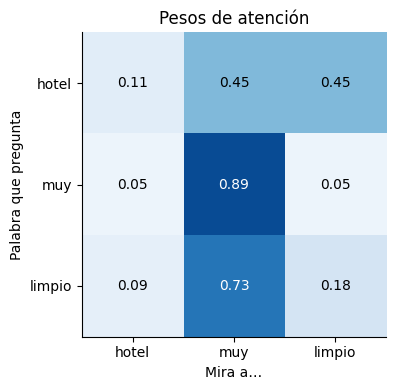

In [27]:
# Crea una figura con un único eje de 4.5x4 pulgadas
fig, ax = plt.subplots(figsize=(4.5, 4))
# Dibuja la matriz como imagen (mapa de calor) en azules, con escala fija 0-1
im = ax.imshow(pesos, cmap="Blues", vmin=0, vmax=1)
# Pone las palabras como etiquetas de los ejes X (columnas) e Y (filas)
ax.set_xticks(range(3)); ax.set_xticklabels(palabras); ax.set_yticks(range(3)); ax.set_yticklabels(palabras)
# Recorre las filas (palabra que pregunta)
for i in range(3):
    # Recorre las columnas (palabra a la que mira)
    for j in range(3):
        # Escribe el peso en la casilla (x = columna, y = fila); blanco si el fondo es oscuro (≥ 0.6)
        ax.text(j, i, f"{pesos[i, j]:.2f}", ha="center", va="center", color="black" if pesos[i, j] < .6 else "white")
# Títulos de los ejes y del gráfico
ax.set_xlabel("Mira a…"); ax.set_ylabel("Palabra que pregunta"); ax.set_title("Pesos de atención")
# Ajusta márgenes y muestra el gráfico
plt.tight_layout(); plt.show()

### ✏️ A12 · EJERCICIO 5 de 6 — Atención con máscara causal

**Tu turno:** Completa `atencion_causal(X, Wq, Wk, Wv)`: igual que `atencion`, pero antes del softmax pon `-1e9` en las posiciones **por encima de la diagonal** (`np.triu(..., k=1)`).

**Debe salir:** una matriz de pesos con ceros por encima de la diagonal (`[[1, 0, 0], [0.06, 0.94, 0], [0.09, 0.73, 0.18]]`) y ✔ Ejercicio 5 correcto

Cambia los `...` y pulsa ▶.

🧠 **Autoejercicio:** cuando salga ✔, responde (respuestas en la Parte B, A12).

1. ¿Cuánto vale `pesos_c[0, 0]` y por qué?
   > ✍️ **Respuesta:** **1,0**: «hotel» es la primera palabra, no tiene palabras anteriores y las futuras están enmascaradas, así que solo puede mirarse a sí misma.
2. ¿Por qué se pone `-1e9` antes del softmax y no 0 después?
   > ✍️ **Respuesta:** Porque exp(−1e9) ≈ 0 y el softmax **renormaliza** el resto: las filas siguen sumando 1. Si pusiéramos 0 *después* del softmax, las filas ya no sumarían 1; y poner 0 *antes* tampoco sirve, porque exp(0) = 1 daría peso a las palabras futuras.
3. ¿Por qué necesita un LLM la máscara causal?
   > ✍️ **Respuesta:** Porque genera texto **de izquierda a derecha**: al predecir un token, los siguientes todavía no existen. En el entrenamiento ve la frase entera, y sin máscara «haría trampa» mirando la palabra que tiene que predecir.

✅ ¿Dudas de tu código? Compáralo con la solución de referencia en la Parte B, A12, **después de intentarlo**.

In [28]:
# Igual que atencion, pero cada palabra solo puede mirar a sí misma y a las anteriores
def atencion_causal(X, Wq, Wk, Wv):
    # pista: igual que atencion, pero con una máscara booleana del triángulo superior (np.triu, k=1) puesta a -1e9 antes del softmax
    # Proyecciones Q, K, V
    Q, K, V = X @ Wq, X @ Wk, X @ Wv
    # Puntuaciones escaladas por √d (pasos 1 y 2)
    p = (Q @ K.T) / np.sqrt(K.shape[1])
    # ones_like: matriz de unos 3x3; triu(k=1): solo el triángulo por encima de la diagonal; == 1 -> máscara booleana (True = futuro)
    mascara = np.triu(np.ones_like(p), k=1) == 1
    # Indexación booleana: pone -1e9 (≈ -∞) en las posiciones futuras
    p[mascara] = -1e9
    # exp(-1e9) ≈ 0, así que el futuro recibe peso 0 y cada fila sigue sumando 1
    pesos = softmax(p)
    # Salida (mezcla de V) y pesos
    return pesos @ V, pesos

# _ descarta la salida; solo nos interesan los pesos
_, pesos_c = atencion_causal(X, Wq, Wk, Wv)
# Muestra los pesos con máscara
print(pesos_c)
# Por encima de la diagonal (futuro) todo debe ser 0
assert np.allclose(np.triu(pesos_c, k=1), 0), "Los pesos por encima de la diagonal (futuro) deben ser 0."
# Cada fila sigue sumando 1
assert np.allclose(pesos_c.sum(axis=1), 1), "Cada fila sigue sumando 1."
# La primera palabra solo se puede mirar a sí misma
assert np.isclose(pesos_c[0, 0], 1.0), "La primera palabra solo puede mirarse a sí misma."
# Ejercicio correcto
print("✔ Ejercicio 5 correcto")


[[1.   0.   0.  ]
 [0.06 0.94 0.  ]
 [0.09 0.73 0.18]]
✔ Ejercicio 5 correcto


### 👀 A13 · EJEMPLO — Temperatura: cómo cambia la distribución

Pulsa ▶ y mira lo que sale. **No hay que escribir nada.**

🧠 **Autoejercicio:** mira el resultado y responde (respuestas en la Parte B, A13).

1. ¿Qué palabra es la más probable en las tres temperaturas?
   > ✍️ **Respuesta:** **«limpio»** (el logit más alto, 3,0) en las tres.
2. ¿Qué le pasa a la distribución cuando sube la temperatura?
   > ✍️ **Respuesta:** Se **aplana**: la probabilidad se reparte más entre todas las palabras (más variedad, menos predecible).
3. ¿Qué riesgo tiene una temperatura alta?
   > ✍️ **Respuesta:** Que elija tokens poco probables: respuestas incoherentes, errores y **alucinaciones** (datos inventados).

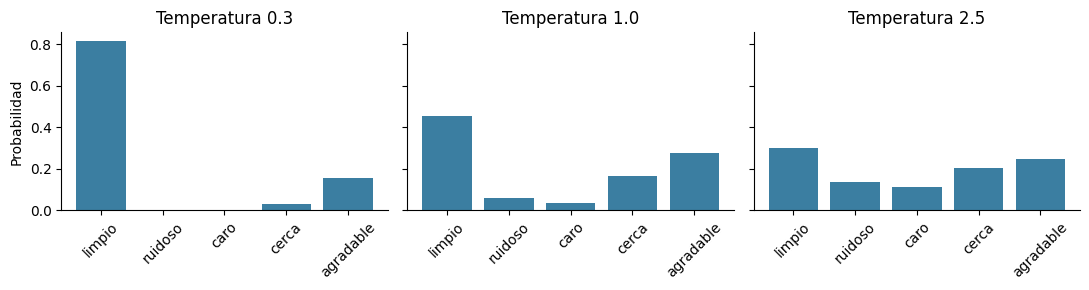

In [29]:
# 5 palabras candidatas para continuar la frase
siguiente = ["limpio", "ruidoso", "caro", "cerca", "agradable"]
# Puntuaciones brutas (logits) de cada candidata; matriz 1x5 porque softmax trabaja por filas
logits = np.array([[3.0, 1.0, 0.5, 2.0, 2.5]])
# 1 fila con 3 gráficos que comparten el eje Y
fig, ejes = plt.subplots(1, 3, figsize=(11, 3), sharey=True)
# Empareja cada eje con una temperatura: 0.3, 1.0 y 2.5
for ax, T in zip(ejes, [0.3, 1.0, 2.5]):
    # Divide los logits entre T y aplica softmax; [0] toma la única fila
    p = softmax(logits / T)[0]
    # Barras de probabilidad, título con la T y etiquetas X rotadas 45°
    ax.bar(siguiente, p, color="#3b7ea1"); ax.set_title(f"Temperatura {T}"); ax.tick_params(axis="x", rotation=45)
# Etiqueta del eje Y solo en el primer gráfico
ejes[0].set_ylabel("Probabilidad")
# Ajusta márgenes y muestra
plt.tight_layout(); plt.show()

### ✏️ A14 · EJERCICIO 6 de 6 — Probabilidad máxima con T baja y alta

**Tu turno:** Calcula `prob_max_T03` (la probabilidad del token más probable con `T = 0.3`) y `prob_max_T25` (con `T = 2.5`). ¿Cuál de las dos es mayor? Escribe la respuesta en `mas_seguro`: `"T baja"` o `"T alta"`.

**Debe salir:** `0.816 0.302 T baja` y ✔ Ejercicio 6 correcto

Cambia los `...` y pulsa ▶.

🧠 **Autoejercicio:** cuando salga ✔, responde (respuestas en la Parte B, A14).

1. ¿Qué probabilidades máximas salen con T = 0,3 y con T = 2,5?
   > ✍️ **Respuesta:** **0,816** con T = 0,3 y **0,302** con T = 2,5.
2. ¿Cuál de las dos temperaturas es «más segura»?
   > ✍️ **Respuesta:** **T baja (0,3)**: concentra la probabilidad en el token más probable, respuestas más predecibles.
3. ¿Qué temperatura usarías para un asistente que responde datos de reservas?
   > ✍️ **Respuesta:** Una **temperatura baja** (≈ 0–0,2): con datos de reservas importan la exactitud y la reproducibilidad, no la creatividad.

✅ ¿Dudas de tu código? Compáralo con la solución de referencia en la Parte B, A14, **después de intentarlo**.

In [30]:
# pista: softmax(logits / T) y .max(); la temperatura baja concentra la probabilidad
# Probabilidad del token más probable con T = 0.3 (float convierte np.float64 a float de Python)
prob_max_T03 = float(softmax(logits / 0.3).max())
# Lo mismo con T = 2.5
prob_max_T25 = float(softmax(logits / 2.5).max())
# Expresión condicional: 'T baja' si con T baja la probabilidad máxima es mayor
mas_seguro = "T baja" if prob_max_T03 > prob_max_T25 else "T alta"

# Muestra ambas probabilidades (3 decimales) y la conclusión
print(round(prob_max_T03, 3), round(prob_max_T25, 3), mas_seguro)
# Con T más baja la distribución es más puntiaguda
assert 0 < prob_max_T25 < prob_max_T03 <= 1, "Con T más baja la distribución es más puntiaguda: prob_max_T03 debe ser mayor."
# La temperatura baja es la más predecible
assert mas_seguro == "T baja", "mas_seguro: la temperatura baja da respuestas más predecibles."
# Ejercicio correcto
print("✔ Ejercicio 6 correcto")


0.816 0.302 T baja
✔ Ejercicio 6 correcto


### ✏️ A15 · MINI-RETO — Que «hotel» preste más atención a «limpio»

**Tu turno:** Con las mismas matrices Wq, Wk y Wv, modifica el embedding de "limpio" para que la palabra "hotel" le **preste más atención**. Crea `X2` (una copia de `X` con la fila de "limpio", índice 2, cambiada) para que `pesos_nuevos[0, 2]` (cuánto mira "hotel" a "limpio") sea **mayor** que `pesos[0, 2]` (la atención original). Guarda en `subio` (True/False) el resultado de la comparación.

**Debe salir:** `Antes: 0.446 | Ahora: 0.932` y ✔ Mini-reto correcto

Cambia los `...` y pulsa ▶.

🧠 **Autoejercicio:** cuando salga ✔, responde (respuestas en la Parte B, A15).

1. ¿Cuánta atención presta «hotel» a «limpio» antes y después?
   > ✍️ **Respuesta:** Antes **0,446**, después **0,932**.
2. ¿Por qué sube al duplicar el embedding de «limpio»?
   > ✍️ **Respuesta:** Porque K_limpio = X2[2] @ Wk también se duplica ([2, 1] → [4, 2]), así que la puntuación Q_hotel · K_limpio pasa de 4 a 8. El softmax amplifica las diferencias de forma exponencial: fila de «hotel» = softmax([2, 4, 8]/√2) → 0,932 para «limpio».
3. ¿Qué otras cosas controlan a qué mira cada palabra?
   > ✍️ **Respuesta:** Las matrices aprendidas **Wq y Wk** (y Wv para el contenido), los **embeddings**, la **codificación posicional**, la **máscara causal**, el escalado √d y el uso de **varias cabezas y capas** de atención.

In [31]:
# pista: multiplica por 2 la fila de "limpio" en X2: sus claves K aumentan y hotel le presta más atención
# Copia independiente de X (con X2 = X se modificaría también X)
X2 = X.copy()
# Duplica el embedding de 'limpio' (fila 2)
X2[2] = X2[2] * 2
# Recalcula la atención con X2 y se queda con los pesos
_, pesos_nuevos = atencion(X2, Wq, Wk, Wv)
# ¿'hotel' (fila 0) mira ahora más a 'limpio' (col 2)? bool convierte np.bool_ a bool
subio = bool(pesos_nuevos[0, 2] > pesos[0, 2])

# Compara la atención antes y después
print("Antes:", round(float(pesos[0, 2]), 3), "| Ahora:", round(float(pesos_nuevos[0, 2]), 3))
# X2 debe tener la misma forma que X
assert X2.shape == X.shape, "X2 debe tener la misma forma que X."
# X2 debe haber cambiado
assert not np.allclose(X2, X), "Modifica X2 para que no sea igual a X."
# La atención de hotel hacia limpio debe haber subido
assert subio, "Ajusta X2 hasta que hotel preste más atención a limpio que antes (pesos_nuevos[0, 2] > pesos[0, 2])."
# Mini-reto correcto
print("✔ Mini-reto correcto")

Antes: 0.446 | Ahora: 0.932
✔ Mini-reto correcto


### 👀 A16 · EJEMPLO — Modelos preentrenados de Hugging Face (opcional, requiere internet)

Pulsa ▶ y mira lo que sale. **No hay que escribir nada.**

🧠 **Autoejercicio:** mira el resultado y responde (respuestas en la Parte B, A16).

1. ¿Qué es la clasificación *zero-shot*?
   > ✍️ **Respuesta:** Clasificar textos en **etiquetas que tú inventas** sin darle ningún ejemplo de entrenamiento: un modelo NLI comprueba si la hipótesis «Esta reseña trata de {etiqueta}» se deduce del texto y puntúa cada etiqueta.
2. ¿Qué hay que hacer antes de fiarse de un modelo preentrenado?
   > ✍️ **Respuesta:** **Evaluarlo con tus propios datos**: una muestra de reseñas reales etiquetadas a mano, medir aciertos (accuracy/precisión/recall), revisar errores (ironía, español de Canarias, reseñas mixtas), sesgos, licencia del modelo y privacidad de los datos.

In [32]:
# Interruptor: False = no se ejecuta la parte opcional
USAR_HUGGING_FACE = False   # ← True solo en Colab con internet

# Solo entra si el interruptor está a True
if USAR_HUGGING_FACE:
    # NO VERIFICADO: requiere internet y descarga de modelos
    # Comando mágico de Jupyter/Colab: instala la librería transformers (-q = silencioso)
    %pip install -q transformers
    # pipeline: interfaz de alto nivel para usar modelos preentrenados en una línea
    from transformers import pipeline
    # Dos reseñas de ejemplo (una positiva y una negativa)
    opiniones = ["El desayuno era delicioso y el personal encantador", "Ruido toda la noche y nadie atendía en recepción"]
    # Modelo BERT multilingüe que clasifica el sentimiento de 1 a 5 estrellas
    clasificador = pipeline("sentiment-analysis", model="nlptown/bert-base-multilingual-uncased-sentiment")
    # Devuelve una lista de dicts {'label': ..., 'score': ...}
    print(clasificador(opiniones))
    # Modelo NLI multilingüe para clasificar en etiquetas inventadas sin entrenar
    zero = pipeline("zero-shot-classification", model="MoritzLaurer/mDeBERTa-v3-base-mnli-xnli")
    # Puntúa cada etiqueta; hypothesis_template construye la frase-hipótesis que se comprueba
    print(zero("Nadie atendía en recepción", candidate_labels=["limpieza", "personal", "ruido", "precio"],
               hypothesis_template="Esta reseña trata de {}."))
# Si el interruptor está a False...
else:
    # ...solo avisa de que se ha omitido
    print("Parte opcional omitida (USAR_HUGGING_FACE = False).")

Parte opcional omitida (USAR_HUGGING_FACE = False).


# Parte B · Explicación de cada celda y de cada resultado

Cada apartado lleva el **mismo número** que su celda de la Parte A (A1, A2…). Si una celda no te sale, mira su «Si falla».

#### A1 · Preparación — Preparar las herramientas

**Contexto.** Antes de que TurisData use un LLM como asistente, su equipo debe entender qué hay dentro de la «caja negra»: no es magia, son **matrices y probabilidades**.

- **Qué hace:**
    - Carga `re`, `Counter` (contador), `numpy` y `matplotlib`.
    - `np.set_printoptions(precision=2, suppress=True)` hace que las matrices se impriman con 2 decimales y sin notación científica.
    - Fija la semilla (`SEMILLA`) y un estilo común para los gráficos.
- **Qué debe salir:**
    - `Listo ✔`.
- **Cómo leerlo:**
    - No hay que entender esta celda: solo ejecutarla **la primera**, y otra vez si reinicias el entorno.
- **Si falla:**
    - `NameError: name 'np' is not defined` → no has ejecutado esta celda. Ejecútala y repite la que falló.

## 1. Tokenización: cómo «lee» un LLM

#### A2 · Ejemplo — Contar pares de símbolos (el corazón del BPE)

Un LLM no lee letras ni palabras completas, sino **tokens**: trozos frecuentes de texto.
- Trocear por **palabras** genera vocabularios enormes y no sabe qué hacer con palabras nuevas.
- Trocear por **letras** da secuencias larguísimas.
- **BPE** (*byte pair encoding*) es un punto medio: parte de letras y va **fusionando los pares más frecuentes**
  hasta formar trozos útiles ("desayun" + "o").

Vamos a implementar un BPE de juguete con un mini corpus.

- **Qué hace:**
    - `corpus` es un mini corpus de 8 palabras sobre desayuno y limpieza.
    - `contar_pares(palabras)` recibe cada palabra troceada en símbolos y devuelve un `Counter` con cuántas veces aparece cada par de símbolos consecutivos (`zip(simbolos, simbolos[1:])`).
- **Qué debe salir:**
    - No imprime nada: deja definida la función `contar_pares`.
- **Cómo leerlo:**
    - Esta función es la pieza clave del BPE: el algoritmo repite «contar pares → fusionar el más frecuente».
- **Si falla:**
    - `NameError: name 'Counter' is not defined` → falta ejecutar la celda de preparación.

<details><summary>🧠 Respuestas al autoejercicio (después de intentarlo)</summary>

1. *¿Qué es un par de símbolos consecutivos?* → Dos símbolos **seguidos** dentro de una palabra, por ejemplo `('d', 'e')` en «desayuno».
2. *¿Qué hace el BPE con el par más frecuente?* → Lo **fusiona** en un solo símbolo y repite el proceso.
3. *¿Por qué trocear por letras no es práctico?* → Porque da **secuencias larguísimas**.

</details>

#### A3 · Ejercicio 1 — El par de letras más común

- **Qué hace:**
    - `[list(p) for p in corpus]` trocea cada palabra en letras y `contar_pares(...)` cuenta los pares (`pares`).
    - `pares.most_common(1)[0][0]` toma el par más frecuente (una tupla de 2 letras): `most_common(1)` da una lista con un único par `(par, veces)`, y `[0][0]` extrae el par.
- **Qué debe salir:**
    - `Par más común: ('d', 'e') → 4 veces` y `✔ Ejercicio 1 correcto`.
- **Cómo leerlo:**
    - `('d', 'e')` aparece 4 veces (en «desayuno», «desayunos», «desayunar» y «desayunamos»). Es el primer par que fusionará el BPE.
- **Si falla:**
    - `par_mas_comun debe ser una tupla de dos símbolos, p. ej. ('a', 'r').` → has guardado el par con su cuenta (`most_common(1)[0]`) o la lista entera; falta el segundo `[0]`.
    - `Debe ser el par con más apariciones.` → no has usado `most_common` (o has ordenado al revés).
    - `NameError: name 'contar_pares' is not defined` → falta el ejemplo anterior.

<details><summary>🧠 Respuestas al autoejercicio (después de intentarlo)</summary>

1. *¿Cuál es el par más común y cuántas veces aparece?* → **`('d', 'e')`**, **4** veces.
2. *¿En qué palabras aparece?* → En **desayuno, desayunos, desayunar y desayunamos**.
3. *¿Qué devuelve `most_common(1)`?* → Una **lista con un par** `(elemento, veces)`: por eso hace falta `[0][0]` para sacar solo el par.

</details>

<details><summary>✅ Comprueba tu código: solución de referencia (solo después de intentarlo)</summary>

```python
pares = contar_pares([list(p) for p in corpus])
par_mas_comun = pares.most_common(1)[0][0]
```

**Tu código puede ser distinto y valer**: lo que importa es que salga ✔ y que los valores coincidan con los de «Qué debe salir».

</details>

#### A4 · Ejemplo — Entrenar un BPE de juguete (12 fusiones)

Observa cómo aparecen trozos como `desayun` o `limpi`: el modelo ha "descubierto" raíces sin saber español.
Una palabra nueva como "desayunando" se trocearía reutilizando esos trozos.

- **Qué hace:**
    - `entrenar_bpe(palabras, n_fusiones)` parte de las palabras en letras y, en cada paso, busca el par más frecuente, lo añade a la lista de `fusiones` y lo sustituye en todas las palabras por un solo símbolo.
    - Se entrena con 12 fusiones; después se imprimen las fusiones aprendidas y cómo queda cada palabra.
- **Qué debe salir:**
    - `Fusiones aprendidas: [('d', 'e'), ('de', 's'), ('des', 'a'), ('desa', 'y'), … ('desayun', 'a')]` y una línea por palabra: `desayuno → ['desayun', 'o']`, `limpio → ['limpi', 'o']`, `limpieza → ['limpi', 'e', 'z', 'a']`, `desayunamos → ['desayuna', 'm', 'os']`…
- **Cómo leerlo:**
    - El modelo «descubre» trozos útiles (`desayun`, `limpi`) **sin saber español**, solo contando pares. Una palabra nueva como «desayunando» se trocearía reutilizando esos trozos.
- **¿De dónde sale cada valor?**
    - **12 fusiones** → con solo 8 palabras (67 letras) el número de fusiones decide **cuánto se comprime**. Medido: 0 fusiones → 67 trozos (una letra por trozo) · 4 → 51 · 8 → 35 · **12 → 22 (compresión 3,05)** · 20 → 12 · 30 o más → 8 trozos (**una palabra = un trozo**, y entonces no se reutiliza nada). 12 es un punto medio para ver trozos sueltos como `desayun` y `limpi`, que es lo que interesa enseñar.
    - **y en un modelo real** → los tokenizadores de los LLM hacen del orden de **30 000 a 100 000 fusiones** sobre una gran cantidad de textos; el número se elige como compromiso entre un vocabulario manejable y secuencias cortas. El 12 de aquí es didáctico, no una referencia.
- **Si falla:**
    - `NameError: name 'contar_pares' is not defined` → falta el ejemplo anterior.

<details><summary>🧠 Respuestas al autoejercicio (después de intentarlo)</summary>

1. *¿Qué trozos «descubre» el BPE?* → Raíces como **`desayun`** y **`limpi`**.
2. *¿Cómo queda «limpieza»?* → **`['limpi', 'e', 'z', 'a']`**: la raíz y las letras que no se han fusionado.
3. *¿Qué ventaja tiene frente a trocear por palabras?* → Una palabra **nueva** se puede trocear reutilizando trozos conocidos, sin vocabularios enormes.

</details>

#### A5 · Ejercicio 2 — Razón de compresión del BPE

**Por qué importa en la práctica:** los LLM cobran y se limitan **por tokens**, y el español suele gastar más tokens que el inglés.

- **Qué hace:**
    - `sum(len(t) for t in tokens)` suma cuántos tokens hay en todas las palabras tras las fusiones (`n_tokens_bpe`).
    - `sum(len(p) for p in corpus)` suma las letras de las palabras originales (`n_letras`).
    - `round(n_letras / n_tokens_bpe, 2)` da la razón de compresión (`compresion`).
- **Qué debe salir:**
    - `67 letras → 22 tokens (compresión 3.05x)` y `✔ Ejercicio 2 correcto`.
- **Cómo leerlo:**
    - Cada token sustituye de media a **3,05 letras**: las secuencias son unas tres veces más cortas. Por eso los LLM trabajan con tokens y no con letras.
- **Si falla:**
    - `n_letras es la suma de letras de las palabras del corpus.` → has contado las palabras (`len(corpus)`) en vez de sus letras.
    - `Con las fusiones debe haber menos tokens que letras.` → has sumado sobre el corpus original y no sobre `tokens`.
    - `NameError: name 'tokens' is not defined` → falta el ejemplo anterior.

<details><summary>🧠 Respuestas al autoejercicio (después de intentarlo)</summary>

1. *¿Cuántas letras y cuántos tokens hay y qué compresión resulta?* → **67** letras, **22** tokens y compresión **3,05**.
2. *¿Qué significa una compresión de 3,05?* → Que cada token sustituye de media a **unas 3 letras**.
3. *¿Por qué importa contar tokens en la práctica?* → Porque los LLM **cobran y se limitan por tokens**, y el español suele gastar más que el inglés.

</details>

<details><summary>✅ Comprueba tu código: solución de referencia (solo después de intentarlo)</summary>

```python
n_tokens_bpe = sum(len(t) for t in tokens)
n_letras = sum(len(p) for p in corpus)
compresion = round(n_letras / n_tokens_bpe, 2)
```

**Tu código puede ser distinto y valer**: lo que importa es que salga ✔ y que los valores coincidan con los de «Qué debe salir».

</details>

## 2. Autoatención paso a paso

#### A6 · Ejemplo — Q, K y V con tres palabras

**Idea.** Al leer "El hotel es limpio pero ruidoso", para entender *ruidoso* conviene mirar a *hotel*.
La **atención** deja que cada palabra decida **cuánto mirar a las demás** y mezcle su información.
Se hace con tres versiones de cada palabra:
- **Q (query, "pregunta")**: lo que esta palabra busca.
- **K (key, "etiqueta")**: lo que cada palabra ofrece.
- **V (value, "contenido")**: la información que se pasa.

Pasos: 1) Q·Kᵀ = *puntuaciones* de compatibilidad; 2) dividir por √d; 3) **softmax** por filas → pesos que suman 1;
4) salida = pesos · V.

Usamos **3 palabras** y vectores de tamaño 4, con números enteros para poder seguir las cuentas a mano.

- **Qué hace:**
    - `palabras` son «hotel», «muy» y «limpio»; `X` es su matriz de embeddings inventados (una fila por palabra, 4 números cada una).
    - `Wq`, `Wk` y `Wv` son las matrices que proyectan de 4 a 2 dimensiones (en un modelo real se **aprenden**).
    - `Q, K, V = X @ Wq, X @ Wk, X @ Wv` calcula las tres versiones de cada palabra (`@` es el producto de matrices).
- **Qué debe salir:**
    - Tres matrices de 3 filas y 2 columnas: `Q = [[2, 0], [0, 4], [1, 2]]`, `K = [[1, 1], [2, 2], [2, 1]]` y `V = [[2, 2], [0, 4], [1, 4]]`.
- **Cómo leerlo:**
    - Cada palabra tiene ahora su «pregunta» (Q), su «etiqueta» (K) y su «contenido» (V). Los números son pequeños para poder seguir las cuentas a mano.
- **¿De dónde sale cada valor?**
    - **3 palabras y 2 columnas** → es lo mínimo para **seguir las cuentas a mano**: matrices de 3×2. Son números inventados y pequeños, no salen de ningún modelo.
    - **en un Transformer real** → las matrices `Wq`, `Wk` y `Wv` **se aprenden** durante el entrenamiento, y cada cabeza usa típicamente 64 columnas (por ejemplo, 512 dimensiones repartidas en 8 cabezas).
- **Si falla:**
    - `NameError: name 'np' is not defined` → falta ejecutar la celda de preparación.

<details><summary>🧠 Respuestas al autoejercicio (después de intentarlo)</summary>

1. *¿Qué forma tienen Q, K y V y por qué?* → **3 filas** (una por palabra) y **2 columnas** (las proyecciones pasan de 4 a 2 dimensiones).
2. *¿Qué representan Q, K y V?* → **Q** lo que la palabra busca, **K** lo que ofrece y **V** la información que pasa.
3. *¿De dónde salen `Wq`, `Wk` y `Wv` en un modelo real?* → Se **aprenden durante el entrenamiento**; aquí están inventadas.

</details>

#### A7 · Ejemplo — Paso 1: puntuaciones Q · Kᵀ

**Paso 1: puntuaciones** = Q · Kᵀ. La fila *i*, columna *j* dice cuánto le interesa la palabra *i* la palabra *j*.

- **Qué hace:**
    - `Q @ K.T` multiplica cada «pregunta» por todas las «etiquetas»: la fila *i*, columna *j* mide cuánto le interesa la palabra *i* la palabra *j*.
- **Qué debe salir:**
    - Una matriz 3 × 3: `[[2, 4, 4], [4, 8, 4], [3, 6, 4]]`.
- **Cómo leerlo:**
    - La fila de «hotel» es `[2, 4, 4]`: le interesan por igual «muy» y «limpio» y menos ella misma. La fila de «muy» tiene un `8` en su propia columna: se mira sobre todo a sí misma.
- **Si falla:**
    - `NameError: name 'Q' is not defined` → falta el ejemplo anterior.

<details><summary>🧠 Respuestas al autoejercicio (después de intentarlo)</summary>

1. *¿Cuánto vale la puntuación de «hotel» hacia «limpio»?* → **4**.
2. *¿Qué palabra se mira más a sí misma?* → **«muy»**, con un **8** en su diagonal.
3. *¿Qué mide la fila *i*, columna *j*?* → **Cuánto le interesa** la palabra *i* la palabra *j*.

</details>

#### A8 · Ejercicio 3 — Escribir softmax por filas

**Paso 2: escalar** por √d (d = 2 aquí) para que los números no crezcan demasiado, y **paso 3: softmax**.
El softmax convierte cada fila en probabilidades (positivas, suman 1): `exp(x) / suma(exp(x))`.

- **Qué hace:**
    - `m.max(axis=1, keepdims=True)` da el máximo de cada fila; restarlo evita números enormes al exponenciar (estabilidad numérica) y no cambia el resultado.
    - `np.exp(...)` exponencia y `e / e.sum(axis=1, keepdims=True)` divide cada fila entre su suma: queda una distribución de probabilidad por fila.
    - La comprobación prueba que cada fila suma 1, que entradas iguales dan `1/3` y que un valor mayor recibe más probabilidad.
- **Qué debe salir:**
    - `softmax([[1, 2, 3], [0, 0, 0]]) = [[0.09, 0.24, 0.67], [0.33, 0.33, 0.33]]`.
    - `✔ Ejercicio 3 correcto`.
- **Cómo leerlo:**
    - Softmax convierte cualquier fila de números en **probabilidades** (positivas y que suman 1), conservando el orden: el valor mayor sigue siendo el mayor.
- **Si falla:**
    - `Cada fila de softmax debe sumar 1 (usa axis=1).` → has sumado por columnas o sobre toda la matriz (usa `axis=1` y `keepdims=True`).
    - `Con entradas iguales, todas las probabilidades valen lo mismo.` → has dividido entre otra cosa que la suma de la fila.
    - `Un valor mayor debe recibir más probabilidad.` → falta `np.exp` o has cambiado el orden.

<details><summary>🧠 Respuestas al autoejercicio (después de intentarlo)</summary>

1. *¿Qué devuelve `softmax([[0., 0., 0.]])`?* → **`[[1/3, 1/3, 1/3]]`**: entradas iguales dan probabilidades iguales.
2. *¿Para qué se resta el máximo de cada fila?* → Para **evitar números enormes** al exponenciar; el resultado no cambia.
3. *¿Qué propiedades tiene cada fila del resultado?* → Todos sus valores son **positivos** y **suman 1**.

</details>

<details><summary>✅ Comprueba tu código: solución de referencia (solo después de intentarlo)</summary>

```python
def softmax(m):
    e = np.exp(m - m.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)
```

**Tu código puede ser distinto y valer**: lo que importa es que salga ✔ y que los valores coincidan con los de «Qué debe salir».

</details>

#### A9 · Ejemplo — Pasos 2 y 3: escalar y softmax

**Paso 2: escalar** por √d (d = 2 aquí) para que los números no crezcan demasiado, y **paso 3: softmax**.
El softmax convierte cada fila en probabilidades (positivas, suman 1): `exp(x) / suma(exp(x))`.

- **Qué hace:**
    - `d = K.shape[1]` es el tamaño de las claves (2).
    - `softmax(puntuaciones / np.sqrt(d))` divide las puntuaciones entre √d para que no crezcan demasiado y las convierte en probabilidades por filas (`pesos`).
- **Qué debe salir:**
    - `Pesos de atención (cada fila suma 1):` y la matriz `[[0.11, 0.45, 0.45], [0.05, 0.89, 0.05], [0.09, 0.73, 0.18]]`.
- **Cómo leerlo:**
    - Cada fila reparte el 100 % de la atención: «hotel» mira un 11 % a sí misma y un 45 % a «muy» y a «limpio»; «muy» se mira un 89 % a sí misma.
- **¿De dónde sale cada valor?**
    - **dividir entre √d** → con `d = 2` el efecto apenas se nota (se divide entre 1,41), pero con `d` grande es **imprescindible**. Medido con Q y K aleatorios y 10 palabras (peso máximo medio que recibe cada palabra): d = 2 → 0,26 sin escalar y 0,21 escalado · d = 16 → 0,76 y 0,40 · **d = 64 → 0,81 y 0,30** · d = 256 → 0,91 y 0,39. Sin dividir, cuanto mayor es `d`, más puntuaciones enormes: el *softmax* se queda con una sola palabra (entropía 0,17 con d = 256, frente a 1,78 al escalar; el máximo posible con 10 palabras sería 2,30) y el entrenamiento se atasca.
    - **por qué precisamente √d** → el producto de dos vectores de `d` números tiene una dispersión que crece como √d; dividir entre √d la deja en una escala estable, sin importar `d`.
- **Si falla:**
    - `NameError: name 'softmax' is not defined` → falta el ejercicio 3 (o su 🆘 solución).

<details><summary>🧠 Respuestas al autoejercicio (después de intentarlo)</summary>

1. *¿Cuánta atención presta «hotel» a «limpio»?* → **0,45** (45 %).
2. *¿Y «muy» a sí misma?* → **0,89** (89 %).
3. *¿Por qué se divide entre √d?* → Para que los números **no crezcan demasiado** y el softmax no se sature.

</details>

#### A10 · Ejercicio 4 — La función de atención completa

**Paso 4: salida** = pesos · V. Cada palabra se convierte en una **mezcla** de los contenidos de las demás, según sus pesos.
Ese vector ya "sabe" del contexto.

- **Qué hace:**
    - `Q, K, V = X @ Wq, X @ Wk, X @ Wv` calcula las tres versiones de cada palabra.
    - `softmax(Q @ K.T / np.sqrt(K.shape[1]))` calcula los pesos (pasos 1 a 3).
    - `return pesos @ V, pesos` mezcla los contenidos según los pesos (paso 4) y devuelve la salida y los pesos.
- **Qué debe salir:**
    - `Salida:` y la matriz `[[0.66, 3.78], [0.16, 3.89], [0.35, 3.82]]`, y `✔ Ejercicio 4 correcto`.
- **Cómo leerlo:**
    - Cada fila de la salida es una **mezcla** de los contenidos V de las tres palabras. La primera fila (la de «hotel») ya «sabe» de «muy» y «limpio».
- **Si falla:**
    - `La salida debe tener una fila por palabra y 2 columnas (dimensión de V).` → has devuelto los pesos en lugar de `pesos @ V`.
    - `Los pesos deben coincidir con los calculados paso a paso arriba.` → falta dividir entre `np.sqrt(K.shape[1])` o usar `softmax`.
    - `NameError: name 'softmax' is not defined` → falta el ejercicio 3.

<details><summary>🧠 Respuestas al autoejercicio (después de intentarlo)</summary>

1. *¿Qué forma tiene la salida y qué representa cada fila?* → **(3, 2)**: una fila por palabra, que es una **mezcla** de los contenidos de todas.
2. *¿Cuáles son los 4 pasos de la atención?* → **1)** Q·Kᵀ, **2)** dividir entre √d, **3)** softmax por filas y **4)** multiplicar los pesos por V.
3. *¿Qué devuelve la función además de la salida?* → Los **pesos de atención**.

</details>

<details><summary>✅ Comprueba tu código: solución de referencia (solo después de intentarlo)</summary>

```python
def atencion(X, Wq, Wk, Wv):
    Q, K, V = X @ Wq, X @ Wk, X @ Wv
    pesos = softmax(Q @ K.T / np.sqrt(K.shape[1]))
    return pesos @ V, pesos
```

**Tu código puede ser distinto y valer**: lo que importa es que salga ✔ y que los valores coincidan con los de «Qué debe salir».

</details>

#### A11 · Ejemplo — Mapa de calor de los pesos de atención

- **Qué hace:**
    - `ax.imshow(pesos, cmap="Blues")` dibuja la matriz de pesos como un mapa de calor (más oscuro = más atención).
    - El bucle escribe el valor en cada casilla; los ejes indican qué palabra pregunta (filas) y a cuál mira (columnas).
- **Qué debe salir:**
    - Un cuadrado de 3 × 3 con los pesos (`0.11 0.45 0.45 / 0.05 0.89 0.05 / 0.09 0.73 0.18`) y el título «Pesos de atención».
- **Cómo leerlo:**
    - La casilla más oscura es «muy» mirándose a sí misma (0,89). Las filas suman 1.
- **Si falla:**
    - `NameError: name 'pesos' is not defined` → falta el ejemplo de los pasos 2 y 3.

<details><summary>🧠 Respuestas al autoejercicio (después de intentarlo)</summary>

1. *¿Qué casilla tiene la atención más alta?* → **«muy» hacia «muy»**, con **0,89**.
2. *¿Qué indican las filas y las columnas?* → Las **filas**, la palabra que pregunta; las **columnas**, la palabra a la que mira.
3. *¿Por qué cada fila suma 1?* → Porque es una **distribución de probabilidad**: la atención de cada palabra se reparte entre las demás.

</details>

## 3. Máscara causal: mirar solo hacia atrás

#### A12 · Ejercicio 5 — Atención con máscara causal

Un LLM genera texto **de izquierda a derecha**: al predecir la palabra 2, no puede ver la 3 (aún no existe).
Se consigue **poniendo −∞ en las puntuaciones de las palabras futuras** antes del softmax: su peso pasa a 0.

- **Qué hace:**
    - `p = Q @ K.T / np.sqrt(K.shape[1])` son las puntuaciones escaladas.
    - `np.triu(np.ones_like(p), k=1) == 1` marca las posiciones **por encima de la diagonal** (las palabras futuras) y `p[mascara] = -1e9` las deja muy negativas.
    - `softmax(p)` convierte esos valores en pesos prácticamente cero para el futuro; `pesos @ V` es la salida.
- **Qué debe salir:**
    - La matriz `[[1, 0, 0], [0.06, 0.94, 0], [0.09, 0.73, 0.18]]` y `✔ Ejercicio 5 correcto`.
- **Cómo leerlo:**
    - La primera palabra solo puede mirarse a sí misma (1,0); la segunda, a la primera y a sí misma; la tercera, a las tres (por eso su fila es idéntica a la sin máscara). Así un LLM **no ve el futuro** al generar.
- **Si falla:**
    - `Los pesos por encima de la diagonal (futuro) deben ser 0.` → la máscara se aplica después del softmax o se ha puesto `0` en lugar de `-1e9` antes de él.
    - `Cada fila sigue sumando 1.` → has enmascarado los pesos ya calculados, así que ya no suman 1; hay que enmascarar las **puntuaciones** y aplicar el softmax después.
    - `NameError: name 'atencion' is not defined`/`'softmax'` → faltan los ejercicios anteriores.

<details><summary>🧠 Respuestas al autoejercicio (después de intentarlo)</summary>

1. *¿Cuánto vale `pesos_c[0, 0]` y por qué?* → **1,0**: la primera palabra solo puede mirarse a sí misma.
2. *¿Por qué se pone `-1e9` antes del softmax y no 0 después?* → Porque `exp(-1e9) ≈ 0` hace que el peso sea 0 **y las filas sigan sumando 1**.
3. *¿Por qué necesita un LLM la máscara causal?* → Porque genera **de izquierda a derecha**: al predecir una palabra, las siguientes aún no existen.

</details>

<details><summary>✅ Comprueba tu código: solución de referencia (solo después de intentarlo)</summary>

```python
def atencion_causal(X, Wq, Wk, Wv):
    Q, K, V = X @ Wq, X @ Wk, X @ Wv
    p = Q @ K.T / np.sqrt(K.shape[1])
    mascara = np.triu(np.ones_like(p), k=1) == 1
    p[mascara] = -1e9
    pesos = softmax(p)
    return pesos @ V, pesos
```

**Tu código puede ser distinto y valer**: lo que importa es que salga ✔ y que los valores coincidan con los de «Qué debe salir».

</details>

## 4. Logits, softmax y temperatura

#### A13 · Ejemplo — Temperatura: cómo cambia la distribución

Al final, un LLM produce para cada posible siguiente token una puntuación (**logit**). El softmax las convierte en
probabilidades y se **elige** una. La **temperatura** T reparte esas probabilidades: T baja → siempre lo más probable (seguro, repetitivo);
T alta → más variedad (creativo, más riesgo de errores/alucinaciones).

- **Qué hace:**
    - `siguiente` son 5 palabras candidatas para continuar una frase y `logits` sus puntuaciones.
    - Para cada temperatura (0,3; 1; 2,5), `softmax(logits / T)` calcula las probabilidades y se dibujan en barras.
- **Qué debe salir:**
    - Tres gráficos de barras (T = 0,3, 1 y 2,5) con las probabilidades de «limpio», «ruidoso», «caro», «cerca» y «agradable».
- **Cómo leerlo:**
    - Con **T = 0,3** casi toda la probabilidad (≈ 0,82) va a «limpio»; con **T = 1** se reparte (≈ 0,46 «limpio», 0,28 «agradable»); con **T = 2,5** queda casi plana. Temperatura baja = seguro y repetitivo; alta = variado y con más riesgo de errores.
- **¿De dónde sale cada valor?**
    - **T = 0,3 · 1 · 2,5** → tres valores para ver **tres comportamientos**: concentrado, neutro y casi plano. Medido con estas mismas puntuaciones: T = 0,1 → 0,99 para «limpio» (casi determinista) · 0,3 → 0,82 · **1 → 0,46** · 2,5 → 0,30 · 10 → 0,22 (casi uniforme: con 5 palabras, 0,20 sería el reparto exacto). Por debajo de 0,1 o por encima de 5 no se aprende nada nuevo.
    - **en uso real** → los asistentes usan temperaturas entre 0 y 1: **cerca de 0** para tareas con una respuesta correcta (código, datos), **0,7–1** para escritura creativa. No hay un valor «bueno»: depende de si se prefiere fiabilidad o variedad.
- **Si falla:**
    - `NameError: name 'softmax' is not defined` → falta el ejercicio 3.

<details><summary>🧠 Respuestas al autoejercicio (después de intentarlo)</summary>

1. *¿Qué palabra es la más probable en las tres temperaturas?* → **«limpio»** (es la de mayor logit), aunque con distinta probabilidad.
2. *¿Qué le pasa a la distribución cuando sube la temperatura?* → Se **aplana**: las probabilidades se reparten más.
3. *¿Qué riesgo tiene una temperatura alta?* → Más **variedad pero también más errores** o invenciones (alucinaciones).

</details>

#### A14 · Ejercicio 6 — Probabilidad máxima con T baja y alta

- **Qué hace:**
    - `softmax(logits / 0.3).max()` es la probabilidad del token más probable con T = 0,3; con `2.5`, la de T = 2,5 (`float(...)` la convierte a un número normal).
    - `mas_seguro` es `"T baja"` si la probabilidad máxima con T baja es mayor, y `"T alta"` si no.
- **Qué debe salir:**
    - `0.816 0.302 T baja` y `✔ Ejercicio 6 correcto`.
- **Cómo leerlo:**
    - Con T = 0,3 el modelo elige «limpio» el **81,6 %** de las veces; con T = 2,5, solo el **30,2 %**. La temperatura baja da respuestas más predecibles.
- **Si falla:**
    - `Con T más baja la distribución es más puntiaguda: prob_max_T03 debe ser mayor.` → has dividido los logits entre otro valor o has intercambiado las dos temperaturas.
    - `mas_seguro: la temperatura baja da respuestas más predecibles.` → has escrito `"T alta"` o un texto distinto de `"T baja"`/`"T alta"`.
    - `NameError: name 'logits' is not defined` → falta el ejemplo anterior.

<details><summary>🧠 Respuestas al autoejercicio (después de intentarlo)</summary>

1. *¿Qué probabilidades máximas salen con T = 0,3 y con T = 2,5?* → **0,816** y **0,302**.
2. *¿Cuál de las dos temperaturas es «más segura»?* → La **baja** (T = 0,3): concentra la probabilidad en lo más probable.
3. *¿Qué temperatura usarías para un asistente que responde datos de reservas?* → Una **baja**: queremos respuestas **predecibles** y con pocos errores.

</details>

<details><summary>✅ Comprueba tu código: solución de referencia (solo después de intentarlo)</summary>

```python
prob_max_T03 = float(softmax(logits / 0.3).max())
prob_max_T25 = float(softmax(logits / 2.5).max())
mas_seguro = "T baja" if prob_max_T03 > prob_max_T25 else "T alta"
```

**Tu código puede ser distinto y valer**: lo que importa es que salga ✔ y que los valores coincidan con los de «Qué debe salir».

</details>

## 5. Mini-reto: ¿de qué depende que un LLM «mire» bien?

#### A15 · Mini-reto — Que «hotel» preste más atención a «limpio»

- **Qué hace:**
    - `X.copy()` hace una copia de `X` para no modificar la original (`X2`); `X2[2] = X2[2] * 2` duplica el embedding de «limpio» (fila 2).
    - `atencion(X2, Wq, Wk, Wv)` recalcula la atención con el embedding modificado y se queda con los pesos nuevos (`pesos_nuevos`).
    - `bool(pesos_nuevos[0, 2] > pesos[0, 2])` comprueba que «hotel» ahora mira más a «limpio» que antes (`subio`).
- **Qué debe salir:**
    - `Antes: 0.446 | Ahora: 0.932` y `✔ Mini-reto correcto`.
- **Cómo leerlo:**
    - Al duplicar el embedding de «limpio», su clave K se hace mayor y la puntuación de «hotel» hacia «limpio» sube: la atención pasa de **0,45 a 0,93**. La atención depende de los **embeddings** y de las **matrices aprendidas** `Wq` y `Wk`.
- **¿De dónde sale cada valor?**
    - **multiplicar por 2** → es un cambio **grande pero sencillo** para que el efecto se vea claro (de 0,45 a 0,93). Cualquier factor mayor que 1 también sube la atención; con factores cada vez mayores se acercaría a 1,0 sin llegar a pasarse, porque los pesos del *softmax* siempre suman 1.
- **Si falla:**
    - `X2 debe tener la misma forma que X.` → has creado `X2` con otra forma (usa `X.copy()` y cambia solo la fila 2).
    - `Modifica X2 para que no sea igual a X.` → no has cambiado la fila de «limpio».
    - `Ajusta X2 hasta que hotel preste más atención a limpio…` → el cambio no sube `pesos_nuevos[0, 2]`; prueba a multiplicar la fila por un número mayor que 1.
    - `NameError: name 'atencion' is not defined` → falta el ejercicio 4.

<details><summary>🧠 Respuestas al autoejercicio (después de intentarlo)</summary>

1. *¿Cuánta atención presta «hotel» a «limpio» antes y después?* → **0,446** antes y **0,932** después.
2. *¿Por qué sube al duplicar el embedding de «limpio»?* → Porque su **clave K aumenta** y la puntuación Q·K de «hotel» hacia «limpio» crece.
3. *¿Qué otras cosas controlan a qué mira cada palabra?* → Las matrices **`Wq` y `Wk`**, que un modelo real aprende durante el entrenamiento.

</details>

## 6. Opcional: Hugging Face

#### A16 · Ejemplo — Modelos preentrenados de Hugging Face (opcional, requiere internet)

> **⚠️ NO VERIFICADO EN EL TALLER:** necesita instalar `transformers`, descargar modelos de Hugging Face (cientos de MB)
> y conexión a internet. Ejecútalo en **Google Colab** (mejor con GPU: *Entorno de ejecución → Cambiar tipo → GPU T4*).
> Los nombres de modelo pueden cambiar con el tiempo: si uno falla, busca uno equivalente en huggingface.co/models.

- **`sentiment-analysis`**: clasifica el sentimiento con un modelo ya entrenado (sin entrenar nada tú).
- **`zero-shot-classification`**: clasifica un texto en **etiquetas que tú inventas** sin ejemplos de entrenamiento.
- **Fine-tuning ligero** (idea): en vez de reentrenar todo el modelo, se ajusta una parte pequeña (p. ej. capas finales o adaptadores LoRA)
  con tus propios ejemplos. Se ve en teoría; aquí no se ejecuta.

- **Qué hace:**
    - `USAR_HUGGING_FACE = False` desactiva la parte opcional; pásalo a `True` solo en Google Colab con internet.
    - Con `True`, instala `transformers`, carga un modelo de **sentimiento** ya entrenado y uno de clasificación **zero-shot** (etiquetas que tú inventas, sin ejemplos) y los prueba con dos opiniones.
- **Qué debe salir:**
    - Con `False` (lo normal): `Parte opcional omitida (USAR_HUGGING_FACE = False).`
- **Cómo leerlo:**
    - **No verificado en el taller**: necesita descargar modelos de cientos de MB y los nombres pueden cambiar. Los modelos preentrenados permiten clasificar sin entrenar, pero hay que **evaluarlos con tus datos** antes de fiarse.
- **Si falla:**
    - Con `True` y sin internet: error al instalar la librería o al descargar el modelo → déjalo en `False`.

<details><summary>🧠 Respuestas al autoejercicio (después de intentarlo)</summary>

1. *¿Qué es la clasificación *zero-shot*?* → Clasificar un texto en **etiquetas que tú inventas**, sin ejemplos de entrenamiento.
2. *¿Qué hay que hacer antes de fiarse de un modelo preentrenado?* → **Evaluarlo con tus propios datos** (reseñas reales de TurisData).

</details>

## Preguntas de reflexión
1. En el ejercicio de la atención, ¿qué representan las filas y qué las columnas de la matriz de pesos? ¿Por qué cada fila suma 1?
2. ¿Por qué un LLM con temperatura alta puede "inventar" datos (alucinar) con más facilidad?
3. Un modelo cobra por tokens y el español consume más que el inglés: ¿cómo afectaría al coste de un asistente para el cliente?
4. Si usas un modelo preentrenado con `zero-shot`, ¿qué comprobarías antes de fiarte de él con las reseñas reales de TurisData?

<details><summary>Ver respuestas (después de pensarlo)</summary>

1. Las **filas** son la palabra que pregunta y las **columnas** la palabra a la que mira. Cada fila suma 1 porque el softmax la convierte en una distribución de probabilidad: la atención de cada palabra se **reparte** entre todas (100 % en total).
2. Con temperatura alta las probabilidades se **aplanan**: los tokens poco probables tienen más opciones de salir, así que el modelo se aleja de lo más probable y puede producir datos plausibles pero falsos (alucinaciones).
3. El coste sube con los tokens: un texto en español consume **más tokens** que su equivalente en inglés, así que cada conversación cuesta más y se llena antes el límite de contexto. Conviene estimar el gasto con textos reales, resumir y acortar los mensajes.
4. Evaluarlo con una **muestra de reseñas reales etiquetadas a mano**: medir su exactitud (por tema y por clase), mirar los errores (ironía, negaciones), probar con varias redacciones de las etiquetas y comprobar que no envía datos personales a un tercero sin base legal.

</details>

## Resumen: qué has aprendido
- Un LLM trabaja con **tokens** (trozos de texto), obtenidos con métodos como BPE.
- La **autoatención** mezcla la información de todas las palabras según pesos calculados con Q, K y V; un Transformer repite esto en muchas capas y "cabezas".
- La **máscara causal** evita mirar al futuro; la **temperatura** regula la variedad de lo que se genera.
- Los modelos preentrenados (Hugging Face) permiten sentimiento y clasificación *zero-shot* sin entrenar, pero hay que **evaluarlos** con tus datos.